In [2]:
# Instalasi dan import library
%pip install hdbscan matplotlib scikit-learn

import hdbscan
import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler


Note: you may need to restart the kernel to use updated packages.


In [3]:
# Memuat dan menstandardisasi Iris dataset
iris = load_iris()
X = StandardScaler().fit_transform(iris.data)
y_true = iris.target

In [4]:
# Clustering menggunakan HDBSCAN
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=2,
    cluster_selection_method="eom",
)
y_pred = clusterer.fit_predict(X)

In [5]:
# Laporan hasil clustering
cluster_labels = sorted(set(y_pred) - {-1})
cluster_count = len(cluster_labels)
noise_count = int(np.sum(y_pred == -1))
ari = adjusted_rand_score(y_true, y_pred)

print("Dataset: Iris")
print(f"Jumlah data: {len(X)}")
print(f"Jumlah cluster yang terbentuk: {cluster_count}")
print(f"Banyaknya noise: {noise_count}")
print(f"Adjusted Rand Index terhadap label asli: {ari:.3f}")

if ari >= 0.75:
    analysis = "Hasil clustering cukup sesuai dengan label asli karena nilai ARI tinggi."
elif ari >= 0.50:
    analysis = "Hasil clustering cukup mencerminkan label asli, tetapi masih ada perbedaan yang berarti."
else:
    analysis = "Hasil clustering belum sesuai dengan label asli karena nilai ARI relatif rendah."
print(f"Analisis: {analysis}")


Dataset: Iris
Jumlah data: 150
Jumlah cluster yang terbentuk: 2
Banyaknya noise: 0
Adjusted Rand Index terhadap label asli: 0.568
Analisis: Hasil clustering cukup mencerminkan label asli, tetapi masih ada perbedaan yang berarti.


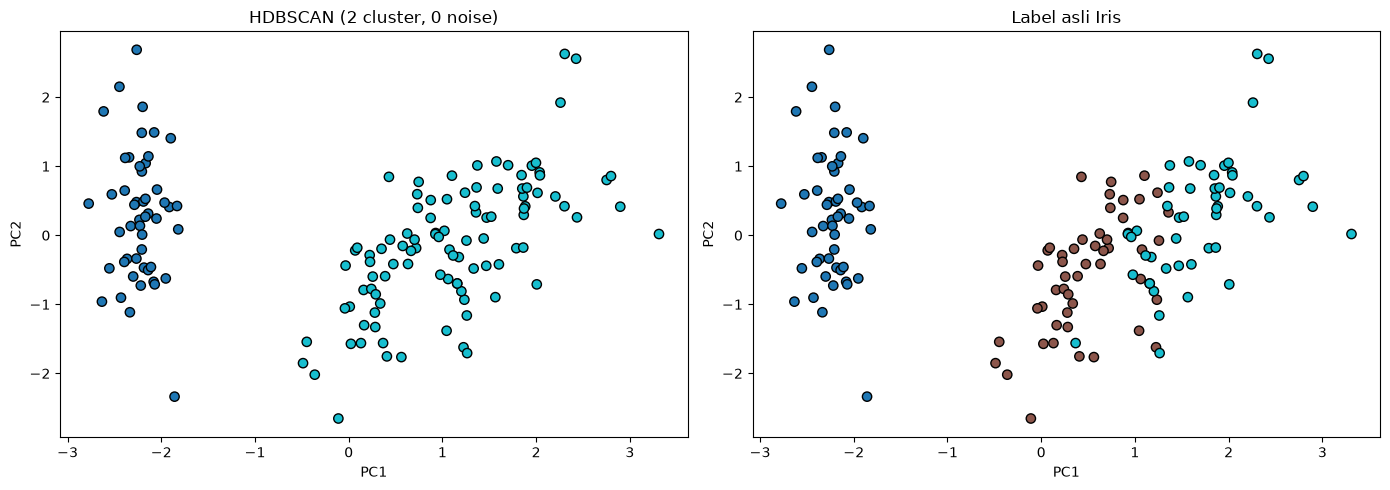

In [6]:
# Reduksi dimensi dengan PCA untuk visualisasi
X_pca = PCA(n_components=2, random_state=42).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

predicted_scatter = axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1], c=y_pred, cmap="tab10", s=45, edgecolor="k"
)
axes[0].set_title(f"HDBSCAN ({cluster_count} cluster, {noise_count} noise)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

true_scatter = axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1], c=y_true, cmap="tab10", s=45, edgecolor="k"
)
axes[1].set_title("Label asli Iris")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()